# Plotting Analysis for Post-Processing

Ted Balabanski

In [25]:
# plotting analysis for the lid-driven cavity solver (post-processing)
# dependencies
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
import re
import sys
import os

# import the plotting utils
from plot import *

# set a color theme for the plots
colors = ["#861F41", "#E5751F", "#642667", "#2A4D14", "#CE0058", "#508590", "#2CD5C4"]

In [20]:
# get the basepath of data
basepath = r"../data/"
datapaths = [name for name in os.listdir(basepath) if os.path.isdir(os.path.join(basepath, name))]

# iterate through each folder in the data file
# and read it in as a parameter, to build a dataframe
paramlist = []
for path in datapaths:
    # read in the parameters
    datafile = os.path.join(basepath, path, "parameters.dat")
    params = read_parameters(datafile)

    # add the filename into it and add it to the dict
    params['file'] = path
    paramlist.append(params)

# build a pandas df of the params of each run
paramdf = pd.DataFrame(paramlist)
paramdf.head(5)

,imms,isgs,imax,jmax,cfl,re,kappa,cx,cy,file
0,0,1,129,129,0.9,100.0,0.1,0.010000,0.010000,nf_129_sgs
1,0,1,65,65,0.9,100.0,0.1,0.062500,0.062500,nf_65_sgs_c0625
2,0,0,33,33,0.9,100.0,0.1,0.010000,0.010000,nf_33_pj
3,0,1,65,65,0.9,100.0,0.1,0.007812,0.007812,nf_65_sgs_c0078
4,0,1,65,65,0.9,100.0,0.1,0.031250,0.031250,nf_65_sgs_c0313


For each of the items below, I've copied the instructions from the project description for my personal reference.

## Instruction item 1. Residual history

Residual history for conservation of mass, x-momentum, and y-momentum:
* Residual comparison between different relaxation methods (PJ, SGS)
* Residual comparison among different mesh sizes (at least two, e.g., 65x65 and 129x129)

First plot the residual comparison between the two methods

In [28]:
plt1df.head()

,imms,isgs,imax,jmax,cfl,re,kappa,cx,cy,file
0,0,1,129,129,0.9,100.0,0.1,0.01,0.01,nf_129_sgs
2,0,0,33,33,0.9,100.0,0.1,0.01,0.01,nf_33_pj
6,0,1,33,33,0.9,100.0,0.1,0.01,0.01,nf_33_sgs
12,0,1,65,65,0.9,100.0,0.1,0.01,0.01,nf_65_sgs
16,0,0,65,65,0.9,100.0,0.1,0.01,0.01,nf_65_pj


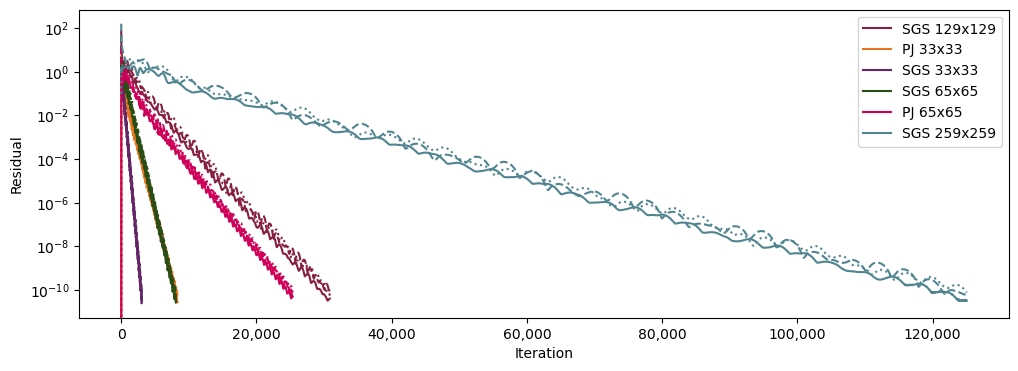

In [47]:
# pull out the 
CFL, RE, KAPPA, CX = 0.9, 100, 0.1, 0.01
plt1df = paramdf[(paramdf.imms == 0) & (paramdf.cfl == CFL) & #(paramdf.imax == 65) &
    (paramdf.re == RE) & (paramdf.kappa == KAPPA) & (paramdf.cx == CX)]

# iterate through each 
fig, ax = plt.subplots(1, 1, figsize=(12,4))

# iterate through each file
for i, file in enumerate(plt1df.file.values):
    # read the consumption history
    hist = read_convergence_history(os.path.join(basepath, file, "history.dat"))

    # plot the history
    label = "SGS" if plt1df.iloc[i, 1] == 1 else "PJ"
    label += " " + str(plt1df.iloc[i,2]) + "x" + str(plt1df.iloc[i,3])
    ax.plot(hist.iteration, hist.resp, linestyle="solid", color=colors[i], label=label)
    ax.plot(hist.iteration, hist.resu, linestyle="dashed", color=colors[i])
    ax.plot(hist.iteration, hist.resv, linestyle="dotted", color=colors[i])

# format the axes
ax.set_xlabel("Iteration")
ax.set_ylabel("Residual")
ax.set_yscale('log')
ax.legend()
ax.get_xaxis().set_major_formatter(FuncFormatter(lambda x, p: "{:,.0f}".format(x)))

plt.show()    